# Why three tasks of the task perturbation fail even with the oracle plan
**VLA direction** · LIBERO-PRO, Object suite · action head trained on ten tasks with the labels of 13 Nov (`s9_align_release10`) · 15 Nov 2026 · a diagnosis from existing rollouts, nothing new was run

- **The question:** under the papers' protocol the action head solves 0.92 of the position perturbation with the oracle plan but only 0.75 of the task perturbation, and three tasks of the latter almost always fail: ketchup (31 of 150), milk (24) and orange juice (54). The plan is right, so the action head does something wrong. What?
- **Real:** the 1500 rollouts per perturbation of the papers' protocol (seeds 7, 8, 9) and their logs; the demonstrations of the ten LIBERO-Object tasks.
- **ORACLE:** the plan given in all these rollouts. The training labels examined in sections 3 and 4 are computed here with the same code that made them for training.

```text
(1) per task: in whose scene it is set, how long the gripper takes, how often it runs out of time
        ↓
(2) one failing rollout next to the same object at the same place in the other perturbation
        ↓
(3) the training labels for "another object named" in these scenes: their path
        ↓
(4) where the last part of the labelled approach comes from
```

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))
from affordance3d.counterfactual import Retarget
from affordance3d.plan_dataset import load_tracks
from affordance3d.plan_input import offsets_from_json
from affordance3d.rollout_log import load_rollout_log
from report import libero_pro_helpers as L
from report import plan_predictor_helpers as P
from report import task_perturbation_helpers as T

set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_colwidth", 60)
PRO = ROOT / "runs" / "libero_pro"
DATA = ROOT / "runs" / "plan_following" / "dataset10"
offsets = offsets_from_json((DATA / "offsets.json").read_text())
SEEDS = (7, 8, 9)
TASK, SWAP = "libero_object_task", "libero_object_swap"


def paths(suite):
    return [path for seed in SEEDS for path in L.episode_paths(PRO / f"full_oracle_s9_seed{seed}", suite)]


# the object that LIBERO-Object's own task k asks for = the target of task k in the position perturbation
scene_targets = {L.task_of(log): log.target for log in L.load_suite(PRO / "full_oracle_s9_seed7", SWAP)}
print(scene_targets)

{0: 'alphabet_soup_1', 1: 'cream_cheese_1', 2: 'salad_dressing_1', 3: 'bbq_sauce_1', 4: 'ketchup_1', 5: 'tomato_sauce_1', 6: 'butter_1', 7: 'milk_1', 8: 'chocolate_pudding_1', 9: 'orange_juice_1'}


## 1 · Per task: whose scene, how long, how often out of time
**This step:** LIBERO-PRO builds each task of the task perturbation on the scene of LIBERO-Object's task with the same index and asks for another object of that scene. For every task: the object asked for, whose scene it is, how far the gripper starts from the grasp point of the object asked for, how far that object stands from the scene's original target, the solved rollouts, when the gripper first comes within 2 cm of the grasp point, how many rollouts never get there or run to the step limit (280), and how many of the first 150 steps the gripper spends almost still (< 2 mm per step) while still more than 5 cm away. The same for the position perturbation below, for reference.

**Status:** real rollouts with the ORACLE plan, three seeds (150 per task).

In [2]:
task_rows = T.task_rows(paths(TASK), scene_targets, offsets)
display(T.task_table(task_rows))
print("position perturbation, for reference:")
display(T.task_table(T.task_rows(paths(SWAP), scene_targets, offsets)))

,asked for,scene of LIBERO-Object task,gripper start to grasp point (cm),original target to the object asked for (cm),solved,step of first reach (median),never reached,ran to the step limit,steps stalled far away (median)
task,,,,,,,,,
0,cream cheese,alphabet soup,25.8,30.2,150 / 150,42.0,4,0,2.0
1,alphabet soup,cream cheese,32.7,21.9,145 / 150,52.0,1,5,3.0
2,tomato sauce,salad dressing,23.3,25.1,131 / 150,42.0,43,19,5.0
3,ketchup,bbq sauce,15.7,25.6,31 / 150,97.5,22,120,14.0
4,milk,ketchup,18.9,17.9,24 / 150,130.0,81,126,31.5
5,bbq sauce,tomato sauce,20.8,25.1,147 / 150,69.0,0,3,11.0
6,orange juice,butter,17.2,30.1,54 / 150,119.0,74,96,30.5
7,butter,milk,41.1,22.4,149 / 150,46.0,0,1,1.0
8,salad dressing,chocolate pudding,33.3,38.2,150 / 150,66.0,0,0,1.0


position perturbation, for reference:


,asked for,scene of LIBERO-Object task,gripper start to grasp point (cm),original target to the object asked for (cm),solved,step of first reach (median),never reached,ran to the step limit,steps stalled far away (median)
task,,,,,,,,,
0,alphabet soup,alphabet soup,23.6,0.0,141 / 150,56.0,4,9,5.0
1,cream cheese,cream cheese,35.0,0.0,150 / 150,48.0,0,0,2.0
2,salad dressing,salad dressing,17.5,0.0,124 / 150,59.0,0,26,8.0
3,bbq sauce,bbq sauce,30.2,0.0,149 / 150,50.0,0,1,1.0
4,ketchup,ketchup,33.7,0.0,104 / 150,55.0,0,46,1.0
5,tomato sauce,tomato sauce,32.4,0.0,142 / 150,48.0,3,8,2.0
6,butter,butter,33.9,0.0,150 / 150,47.0,0,0,2.0
7,milk,milk,27.6,0.0,150 / 150,50.0,0,0,2.0
8,chocolate pudding,chocolate pudding,41.1,0.0,149 / 150,53.0,0,1,3.0


## 2 · One failing rollout next to a solved one with the same object at the same place
**This step:** the orange juice stands at the same place in task 6 of the task perturbation and in task 9 of the position perturbation, and the plan given is the same. Its distance to the grasp point and its height above it, step by step, for one rollout of each (seed 7, start 0), with a ketchup and a milk rollout of the task perturbation; then camera frames of the same rollouts.

**Status:** real rollouts with the ORACLE plan.

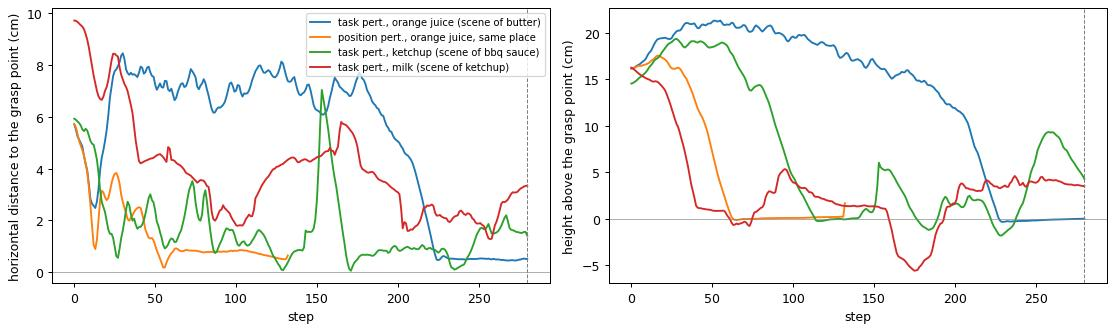

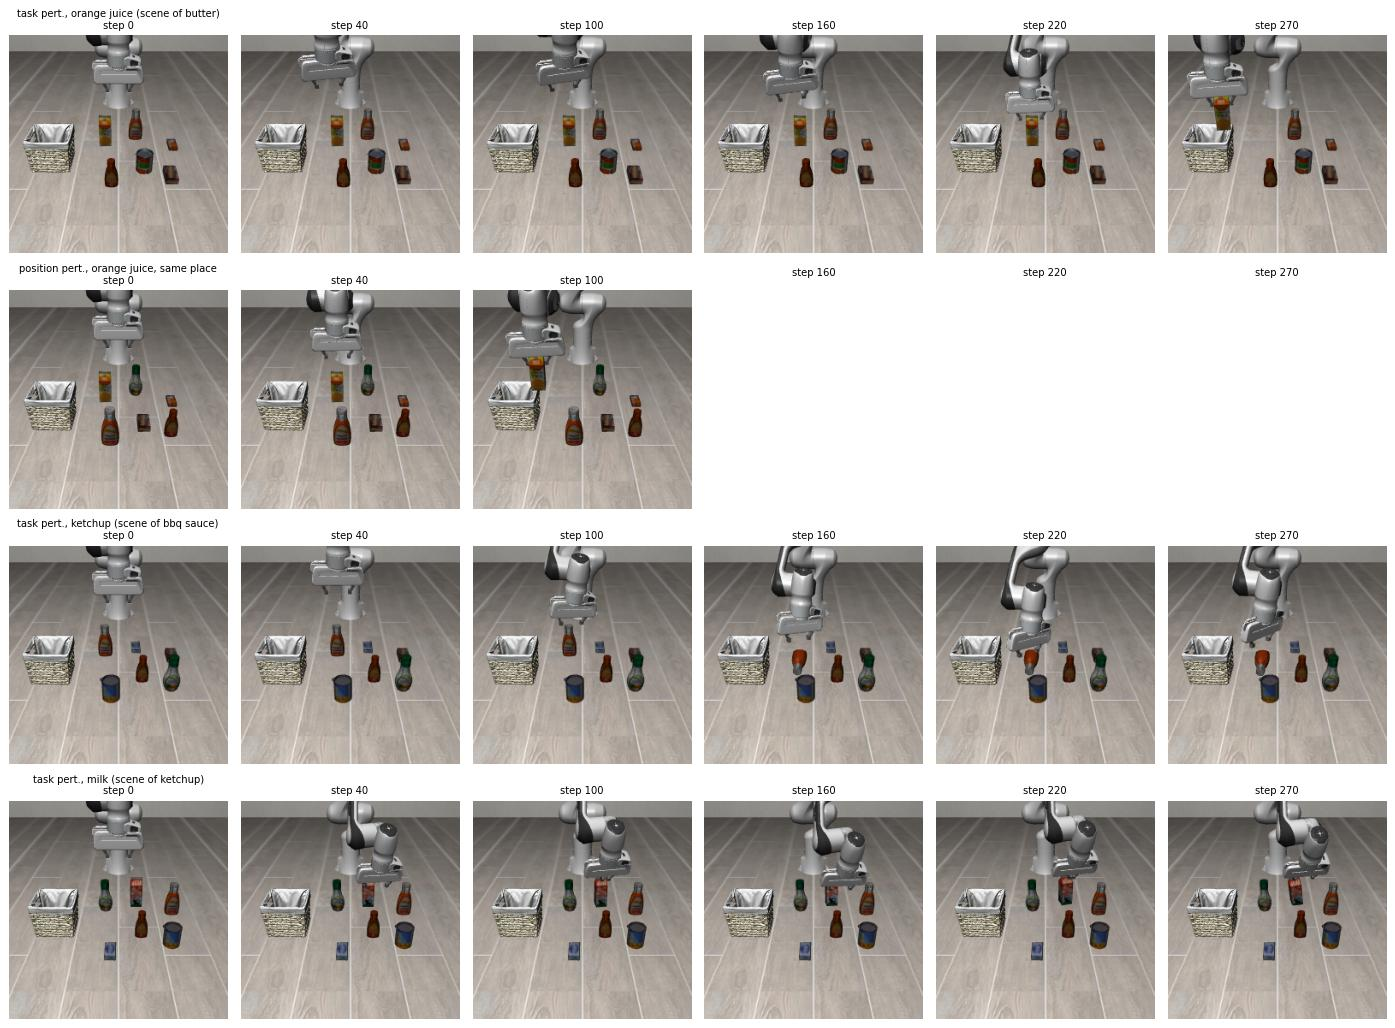

In [3]:
CASES = {"task pert., orange juice (scene of butter)": (TASK, "task6_ep0"),
         "position pert., orange juice, same place": (SWAP, "task9_ep0"),
         "task pert., ketchup (scene of bbq sauce)": (TASK, "task3_ep0"),
         "task pert., milk (scene of ketchup)": (TASK, "task4_ep0")}
logs = {name: load_rollout_log(PRO / "full_oracle_s9_seed7" / suite / f"{stem}.npz")
        for name, (suite, stem) in CASES.items()}
T.course_figure(logs, offsets)
plt.show()
T.frames_figure(logs)
plt.show()

## 3 · The training labels for "another object named" in these scenes
**This step:** for a frame of a demonstration, a training sample that names another object of the scene gets an action label made by moving the demonstrated path (from the gripper to the original target's grasp point) to the other object's grasp point. Here that is done at the first frame of every demonstration of each scene, for the object the task perturbation asks for there, under the two rules used so far: the rule of 11 Nov (the shift blended in until the last 8 cm) and the rule of 13 Nov used by this action head (a shift longer than the path before the last 18 cm made first). For each: the labelled path's length over the straight distance (`detour`), how far it first moves away from the object asked for (`away`), and its lowest height above that grasp point while it is still more than 4 cm aside (`low_aside`). Medians over the demonstrations of the scene.

**Status:** the demonstrations are real; the moved paths are what the training labels asked for.

In [4]:
tracks = load_tracks(DATA / "tracks.npz")
pairs = {row.task: (row.asked, row.scene_of) for row in task_rows}
RULES = {"rule of 11 Nov": Retarget(), "rule of 13 Nov": Retarget(rigid_tail=0.18, align_first=True)}
display(T.label_table(tracks, pairs, offsets, RULES))

,asked for,scene of,demonstrations,"(rule of 11 Nov, detour)","(rule of 11 Nov, away (cm))","(rule of 11 Nov, low_aside (cm))","(rule of 13 Nov, detour)","(rule of 13 Nov, away (cm))","(rule of 13 Nov, low_aside (cm))"
task,,,,,,,,,
0,cream cheese,alphabet soup,42,1.36,4.53,5.31,2.86,16.73,5.38
1,alphabet soup,cream cheese,49,1.34,0.00,8.91,1.41,0.00,15.45
2,tomato sauce,salad dressing,47,1.20,0.00,9.70,2.67,11.23,11.84
3,ketchup,bbq sauce,47,1.87,2.52,6.15,4.37,13.95,11.49
4,milk,ketchup,41,3.08,3.05,-0.63,3.26,2.00,-0.85
5,bbq sauce,tomato sauce,46,1.59,1.61,6.30,1.54,1.47,6.84
6,orange juice,butter,50,1.98,4.20,5.73,4.50,18.03,5.88
7,butter,milk,42,1.29,0.00,12.66,1.59,0.00,5.54
8,salad dressing,chocolate pudding,49,1.57,0.00,11.03,2.79,0.00,7.31


**The orange juice in the scene of the butter, drawn.** One demonstration of the butter task from its first frame, and its path moved to the orange juice under the two rules; dots are the next 8 steps the labels ask for.

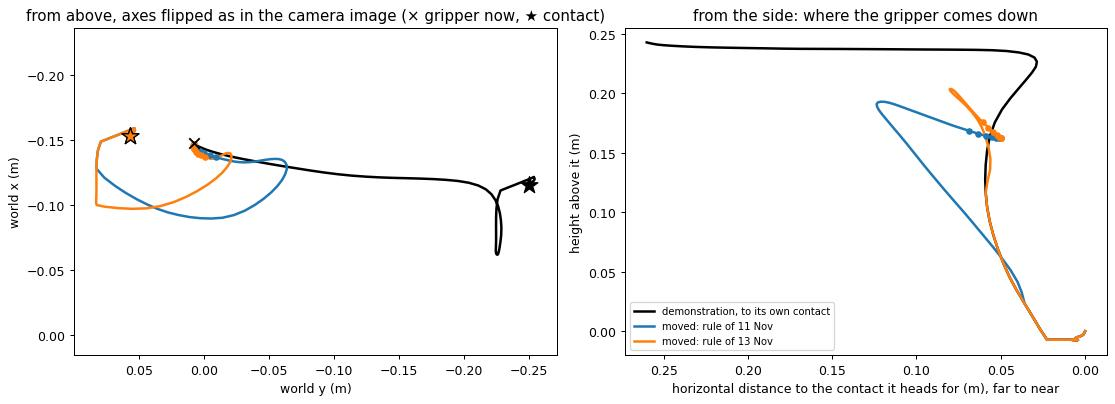

In [5]:
track = next(t for t in tracks if t.target == "butter_1" and "orange_juice_1" in t.names)
path = T.approach_path(track)
juice = track.object_pos[0, track.names.index("orange_juice_1")] + offsets.grasp["orange_juice_1"]
P.retarget_figure(path, juice, RULES)
plt.show()

## 4 · Where the last part of the labelled approach comes from
**This step:** the last part of a moved path keeps the shape of the demonstrated approach to the original target. For each object, the shape of the last 18 cm of its own demonstrated approaches: how high above and how far aside of the grasp point that part starts, and how far it travels sideways while lower than 4 cm.

**Status:** real demonstrations.

In [6]:
display(T.tail_table(tracks))

,demonstrations,start of the last part: height (cm),start of the last part: aside (cm),sideways while lower than 4 cm (cm)
alphabet soup,42,15.0,4.8,2.7
bbq sauce,47,13.8,2.5,2.7
butter,50,14.0,6.0,3.1
chocolate pudding,49,14.7,5.4,2.8
cream cheese,49,15.2,2.9,2.1
ketchup,41,6.1,7.9,4.2
milk,42,13.8,5.2,3.3
orange juice,41,13.0,3.5,2.5
salad dressing,47,12.1,4.0,2.2
tomato sauce,46,14.1,4.3,2.2


## What to take from this

**What the failures are**
- **Mostly running out of time.** In the three tasks the gripper first reaches the grasp point after a median of 98 to 130 steps, against 37 to 69 in the other seven tasks, and 96 to 126 of 150 rollouts run to the step limit. Orange juice and ketchup rollouts spend long stretches nearly still more than 5 cm from the object: the orange juice rollout of section 2 hovers about 20 cm above and 7 cm beside it for 190 steps, then grasps it shortly before the limit. Milk is mostly knocked over (it drops about 4 cm), and ketchup is often touched but not grasped.
- **Not the place.** The orange juice stands at the same place in task 9 of the position perturbation, with the same plan, and is reached by step 54 and solved in 121 of 150 rollouts.

**Why: the training labels for "another object named" in exactly these scenes**
- **They make a detour.** The three tasks are the ones in which the object asked for is closest to where the gripper starts (16 to 19 cm), while the scene's original target is 18 to 30 cm away from it. The label moves the demonstrated path to the original target over to the object asked for. With the rule this action head was trained with, that path is 3.3 to 4.5 times longer than the straight line in these three tasks (1.4 to 2.9 in the other seven), and for ketchup and orange juice it first moves 14 to 18 cm away from the object. The head was trained on these labels for these very scenes and instructions, follows them part of the way, and ends up in states that no demonstration covers. At the place of the position perturbation no such labels were ever made (training shifts stay within 18 cm, this place is 26 cm away), and there the head goes straight.
- **They copy the wrong final approach.** The last part of the moved path keeps the shape of the original target's approach. The ketchup's demonstrations come in low from the side (the last 18 cm start 6 cm above and 8 cm aside, against 12 to 15 cm above for every other object). The milk task is set in the ketchup's scene, so its labels bring the gripper in low beside the tall milk carton, which falls (the labelled path is below the grasp point while still more than 4 cm aside). The ketchup task is set in the bbq sauce's scene and gets its steep approach instead of the ketchup's own. The plan input, by contrast, already gives the approach direction of the object asked for, so plan and label disagree.

**What it does not show**
- That fixing the labels fixes these tasks: that needs a head trained with other labels. A prototype of the first fix below removes the moving away in all ten pairs, but keeps detours of 1.9 to 3.1 for these three, because the moved final approach (18 cm) is as long as the whole straight distance.
- Whether the same holds in the other suites.

**Proposed fix (for the project lead to decide)**
1. Move the free part of the demonstrated path by rotating and scaling it about the gripper's start, so that it heads for the object asked for and shrinks with the distance, instead of adding the shift; the final approach is moved as a whole as before, and shortened when the object is close.
2. Take the final approach from the demonstrations of the object asked for, not from the scene's original target, so that it agrees with the plan's approach direction.
3. Test: one ten-task head with both changes, both perturbations of LIBERO-PRO Object with the oracle plan and with kept map plans, 20 start states; the three tasks should rise and the other seven should not drop.